In [1]:
# Import Library
import os
import keras
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
# Load dataset
PATH = 'dataset/'
CLASS_NAMES = os.listdir(PATH)
print(CLASS_NAMES)

['Cucumber', 'Broccoli', 'Tomato', 'Carrot']


In [3]:
# Load Image
rows, cols = 224, 224
x, y = [], []
counter = 0

for class_name in CLASS_NAMES:
    for img_path in os.listdir(PATH + class_name):
        path = f"{PATH}{class_name}/{img_path}"
        label = counter
        image = tf.keras.preprocessing.image.load_img(path, target_size=(rows, cols), color_mode='grayscale')
        image = tf.keras.preprocessing.image.img_to_array(image)
        x.append(image)
        y.append(label)
    counter += 1
    print(class_name)
    
x = np.array(x)
y = np.array(y)

x = x.astype('float32')/255.0

print(x.shape)
print(y.shape)

Cucumber
Broccoli
Tomato
Carrot
(2000, 224, 224, 1)
(2000,)


In [4]:
# split 80:10:10
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [5]:
# Preprocess OHE
y_train = keras.utils.to_categorical(y_train, num_classes=4)
y_val = keras.utils.to_categorical(y_val, num_classes=4)
y_test = keras.utils.to_categorical(y_test, num_classes=4)

In [9]:
# DCNN

model = keras.Sequential([
    keras.layers.Input(shape=(rows, cols, 1)),
    
    keras.layers.Conv2D(4, (5,5), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2,2), strides=2),
    keras.layers.Conv2D(8, (5,5), activation="relu"),
    keras.layers.Conv2D(16, (5,5), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2,2), strides=2),
    keras.layers.Flatten(),
    
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(4, activation="softmax"),
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 220, 220, 4)    │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 110, 110, 4)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 106, 106, 8)    │           808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 102, 102, 16)   │         3,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 51, 51, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 41616)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     2,663,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,667,876 (10.18 MB)

 Trainable params: 2,667,876 (10.18 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(x_train, y_train, batch_size=32, epochs=10, validation_data=(x_val, y_val))

Epoch 1/10


2026-10-12 00:17:11.513543: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 85ms/step - accuracy: 0.5231 - loss: 1.0470 - val_accuracy: 0.7450 - val_loss: 0.6224
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - accuracy: 0.8081 - loss: 0.4963 - val_accuracy: 0.8400 - val_loss: 0.4467
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 71ms/step - accuracy: 0.8975 - loss: 0.2924 - val_accuracy: 0.7950 - val_loss: 0.5376
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - accuracy: 0.9206 - loss: 0.2288 - val_accuracy: 0.8350 - val_loss: 0.4482
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 72ms/step - accuracy: 0.9463 - loss: 0.1436 - val_accuracy: 0.8500 - val_loss: 0.4671
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - accuracy: 0.9531 - loss: 0.1276 - val_accuracy: 0.8900 - val_loss: 0.3618
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 72ms/step - accuracy: 0.9750 - loss: 0.0751 - val_accuracy: 0.8600 - val_loss: 0.4571
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 72ms/step - accuracy: 0.9750 - loss: 0.0664 - val_accuracy: 0.8550 - val_loss: 0.

In [11]:
# Model Evaluation
model.evaluate(x_test, y_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8550 - loss: 0.6591


[0.6591243147850037, 0.8550000190734863]

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


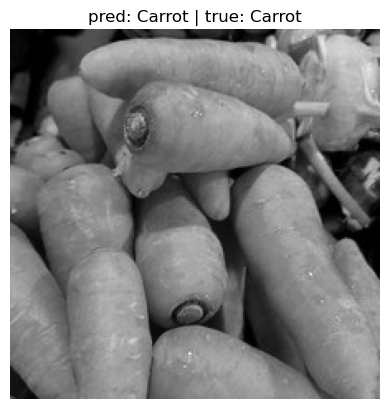

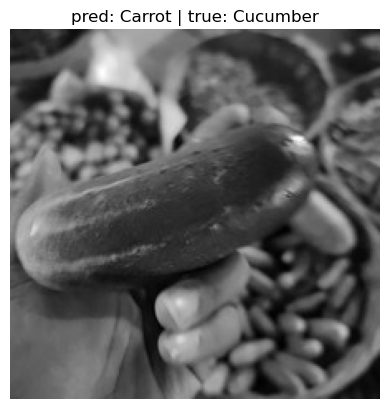

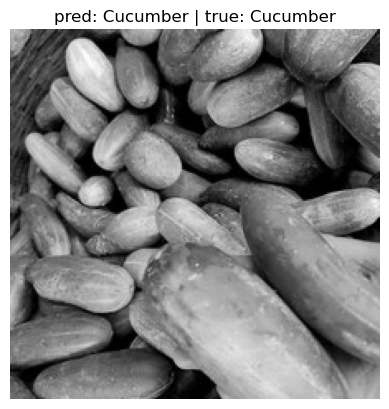

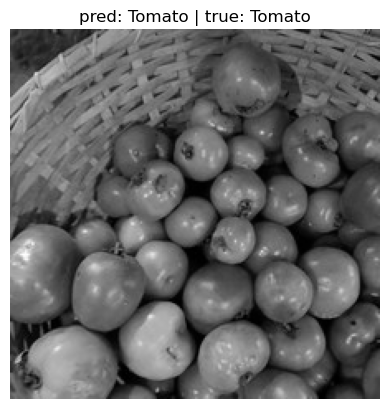

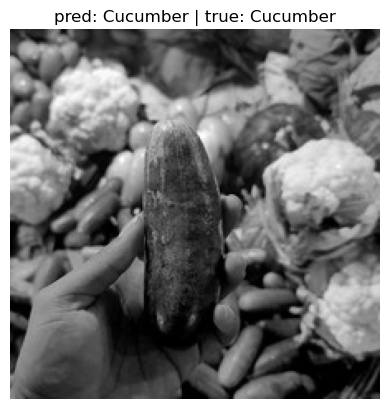

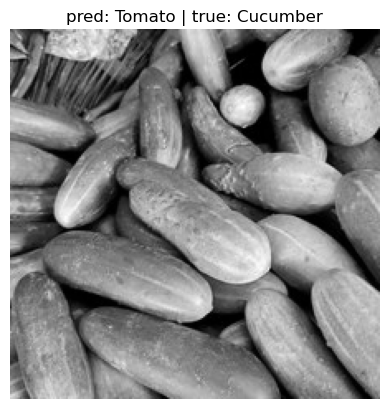

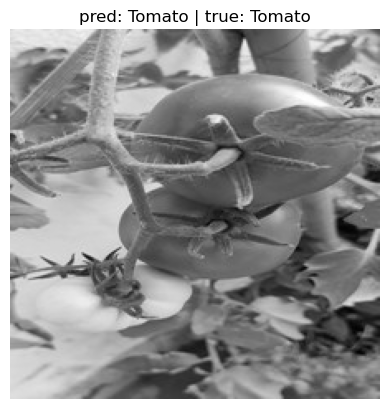

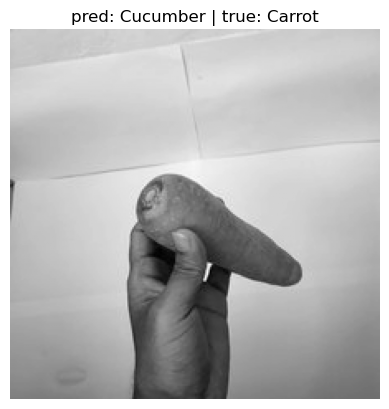

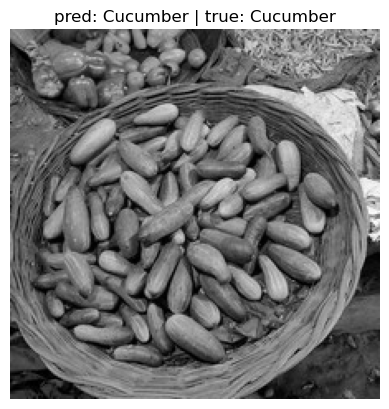

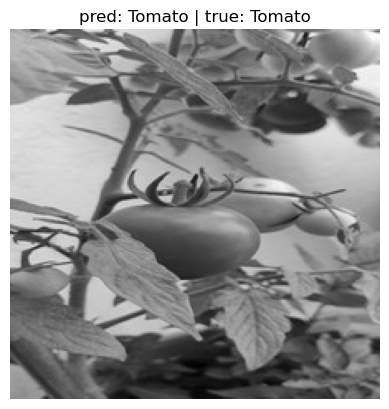

In [13]:
# Model Predict
pred_result = model.predict(x_test)

for i in range(10):
    pred = CLASS_NAMES[np.argmax(pred_result[i])]
    true = CLASS_NAMES[np.argmax(y_test[i])]
    
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title(f"pred: {pred} | true: {true}")
    plt.axis("off")
    plt.show()

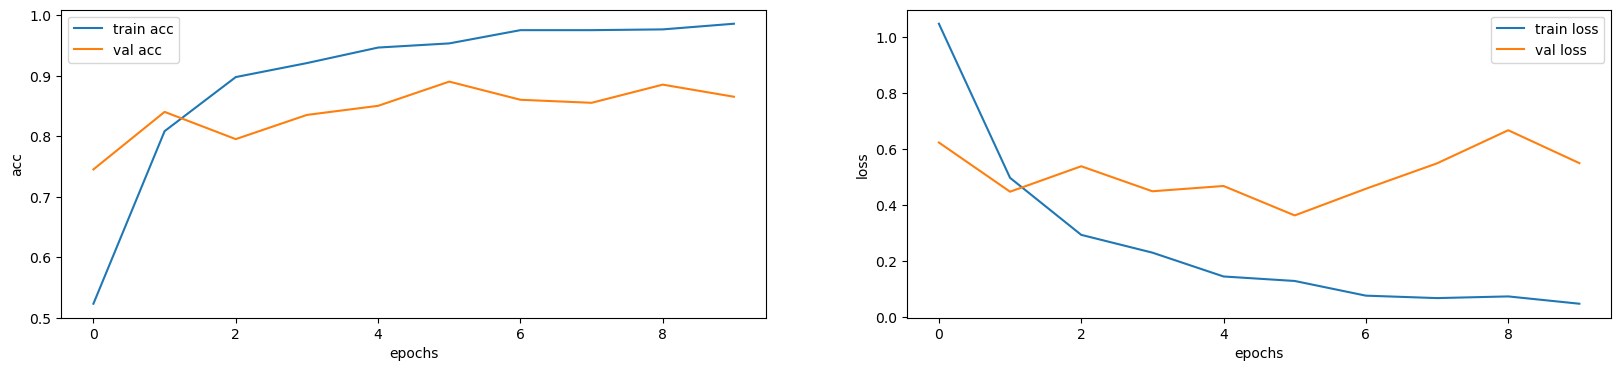

In [14]:
plt.figure(figsize=(20,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label="train acc")
plt.plot(history.history['val_accuracy'], label="val acc")
plt.xlabel("epochs")
plt.ylabel("acc")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label="train loss")
plt.plot(history.history['val_loss'], label="val loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.legend()

plt.show()